# **Classificação de texto com spaCy**

## Etapa 1: Importação e instalação das bibliotecas

In [12]:
import os
import random
import string
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from sklearn.metrics import accuracy_score, confusion_matrix
from spacy.lang.pt.stop_words import STOP_WORDS
from spacy.training import Example


## Etapa 2: Carregamento da base de dados

In [2]:
DRIVE_DIRECTORY = Path.cwd().parent / "data"
MODELS = Path.cwd().parent / "models"

In [3]:
base_dados = pd.read_csv(
    os.path.join(DRIVE_DIRECTORY, "base_treinamento.txt"), encoding="utf-8"
)
base_dados

,texto,emocao
0,este trabalho é agradável,alegria
1,gosto de ficar no seu aconchego,alegria
2,fiz a adesão ao curso hoje,alegria
3,eu sou admirada por muitos,alegria
4,adoro como você,alegria
...,...,...
191,estou chocado e amedrontado com este assassina...,medo
192,é preciso afugenta com ímpeto este medo do inf...,medo
193,políticos usam suas forças para afugentar e am...,medo
194,o objetivo disso e apenas me amedrontar mais,medo


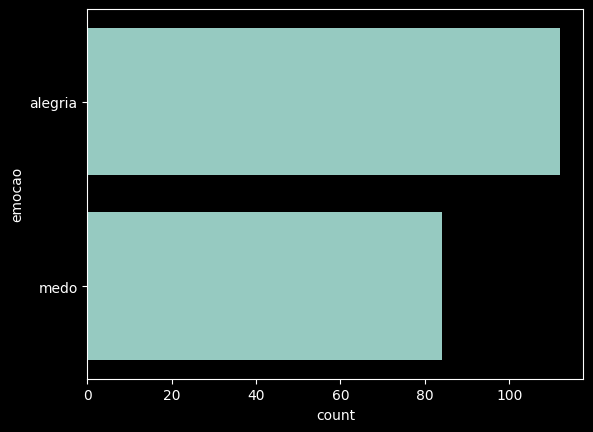

In [21]:
sns.countplot(base_dados["emocao"], label="Contagem");

## Etapa 3: Função para pré-processamento dos textos

In [22]:
pontuacoes = string.punctuation
pontuacoes

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [23]:
stop_words = STOP_WORDS
len(stop_words)

416

In [6]:
pln = spacy.load("pt_core_news_sm")
pln

In [5]:
def preprocessamento(texto):
    texto = texto.lower()
    documento = pln(texto)
    lista = []

    for token in documento:
        lista.append(token.lemma_)

    lista = [
        palavra
        for palavra in lista
        if palavra not in stop_words and palavra not in pontuacoes
    ]
    lista = " ".join([
        str(elemento) for elemento in lista if not elemento.isdigit()
    ])

    return lista

In [26]:
teste = "Estou aprendendo processamento 112233 de linguagem natural, curso em Curitiba"
preprocessamento(teste)

'aprender processamento linguagem natural curso curitber'

## Etapa 4: Pré-processamento da base de dados

### Limpeza dos textos

In [27]:
base_dados.head(10)

,texto,emocao
0,este trabalho é agradável,alegria
1,gosto de ficar no seu aconchego,alegria
2,fiz a adesão ao curso hoje,alegria
3,eu sou admirada por muitos,alegria
4,adoro como você,alegria
5,adoro seu cabelo macio,alegria
6,adoro a cor dos seus olhos,alegria
7,somo tão amáveis um com o outro,alegria
8,sinto uma grande afeição por ele,alegria
9,quero agradar meus filhos,alegria


In [28]:
base_dados['texto'] = base_dados['texto'].apply(preprocessamento)
base_dados

,texto,emocao
0,trabalho agradável,alegria
1,gostar ficar em o aconchego,alegria
2,fiz adesão a o curso hoje,alegria
3,admirar,alegria
4,adorar,alegria
...,...,...
191,chocado amedrontar assassinato brutal,medo
192,preciso afugentar ímpeto medo de o inferno,medo
193,político força afugentar amedrontar,medo
194,objetivo de isso amedrontar,medo


### Tratamento da classe

In [29]:
base_dados_final = []
for texto, emocao in zip(base_dados['texto'], base_dados['emocao']):
    if emocao == 'alegria':
        dic = ({'ALEGRIA': True, 'MEDO': False})
    elif emocao == 'medo':
        dic = ({'ALEGRIA': False, 'MEDO': True})
    base_dados_final.append([texto, dic.copy()])

base_dados_final

[['trabalho agradável', {'ALEGRIA': True, 'MEDO': False}],
 ['gostar ficar em o aconchego', {'ALEGRIA': True, 'MEDO': False}],
 ['fiz adesão a o curso hoje', {'ALEGRIA': True, 'MEDO': False}],
 ['admirar', {'ALEGRIA': True, 'MEDO': False}],
 ['adorar', {'ALEGRIA': True, 'MEDO': False}],
 ['adorar cabelo macio', {'ALEGRIA': True, 'MEDO': False}],
 ['adorar cor de o olho', {'ALEGRIA': True, 'MEDO': False}],
 ['somo amável outro', {'ALEGRIA': True, 'MEDO': False}],
 ['sinto afeição', {'ALEGRIA': True, 'MEDO': False}],
 ['querer agradar filho', {'ALEGRIA': True, 'MEDO': False}],
 ['sinto completamente amar', {'ALEGRIA': True, 'MEDO': False}],
 ['amar', {'ALEGRIA': True, 'MEDO': False}],
 ['alívio', {'ALEGRIA': True, 'MEDO': False}],
 ['dor amenizar finalmente', {'ALEGRIA': True, 'MEDO': False}],
 ['achar apaixonar', {'ALEGRIA': True, 'MEDO': False}],
 ['amar maravilhoso', {'ALEGRIA': True, 'MEDO': False}],
 ['sentir animar', {'ALEGRIA': True, 'MEDO': False}],
 ['sinto hoje', {'ALEGRIA': Tr

## Etapa 5: Criação do classificador

In [30]:
modelo = spacy.blank("pt")
categorias = modelo.add_pipe("textcat")
categorias.add_label("ALEGRIA")
categorias.add_label("MEDO")
historico1 = []
historico2 = []

In [31]:
modelo.initialize()

for epoca in range(500):
    random.shuffle(base_dados_final)
    losses = {}
    for batch in spacy.util.minibatch(base_dados_final, 30):
        exemplos = []
        for texto, entities in batch:
            doc = modelo.make_doc(texto)
            exemplo = Example.from_dict(doc, {"cats": entities})
            exemplos.append(exemplo)

        modelo.update(exemplos, losses=losses)

    if epoca % 100 == 0:
        print(losses)
        historico1.append(losses)

{'textcat': 1.7028688937425613}
{'textcat': 2.5931779293331125e-11}
{'textcat': 3.387380884145065e-12}
{'textcat': 9.02632745565686e-13}
{'textcat': 3.2411662533016715e-13}


In [32]:
modelo.begin_training()
for epoca in range(500):
    random.shuffle(base_dados_final)
    losses = {}
    for batch in spacy.util.minibatch(base_dados_final, 30):
        textos = [modelo(texto) for texto, entities in batch]
        annotations = [{'cats': entities} for texto, entities in batch]
        examples = [Example.from_dict(doc, annotation) for doc, annotation in zip(
            textos, annotations
        )]
        modelo.update(examples, losses=losses)
    if epoca % 100 == 0:
        print(losses)
        historico2.append(losses)

{'textcat': 1.7106920331716537}
{'textcat': 2.5784321075819627e-11}
{'textcat': 3.3719057277240005e-12}
{'textcat': 8.547529613896383e-13}
{'textcat': 3.420130169606286e-13}


In [33]:
historicos_loss1 = []
for i in historico1:
    historicos_loss1.append(i.get('textcat'))
historicos_loss2 = []
for i in historico2:
    historicos_loss2.append(i.get('textcat'))

In [34]:
historicos_loss1 = np.array(historicos_loss1)
historicos_loss2 = np.array(historicos_loss2)
historicos_loss1, historicos_loss2

(array([1.70286889e+00, 2.59317793e-11, 3.38738088e-12, 9.02632746e-13,
        3.24116625e-13]),
 array([1.71069203e+00, 2.57843211e-11, 3.37190573e-12, 8.54752961e-13,
        3.42013017e-13]))

Text(0, 0.5, 'Erro')

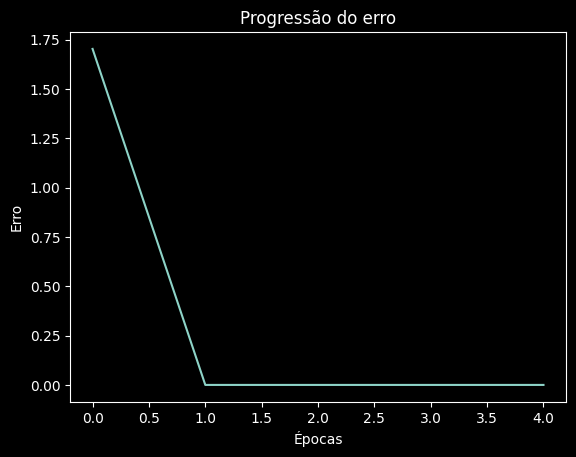

In [35]:
plt.plot(historicos_loss1)
plt.title('Progressão do erro')
plt.xlabel('Épocas')
plt.ylabel('Erro')

Text(0, 0.5, 'Erro')

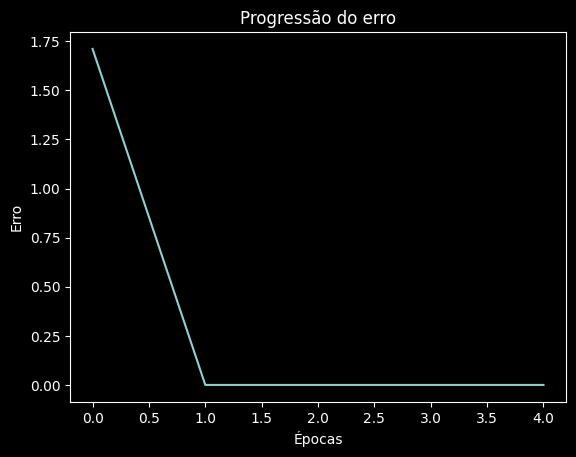

In [36]:
plt.plot(historicos_loss2)
plt.title('Progressão do erro')
plt.xlabel('Épocas')
plt.ylabel('Erro')

In [37]:
modelo.to_disk(os.path.join(MODELS, 'modelo'))

## Etapa 6: Testes com uma frase

In [4]:
modelo_carregado = spacy.load(os.path.join(MODELS, 'modelo'))
modelo_carregado

In [39]:
texto_positivo = 'eu adoro a cor dos seus olhos'
texto_positivo = preprocessamento(texto_positivo)
texto_positivo

'adorar cor de o olho'

In [40]:
previsao = modelo_carregado(texto_positivo)
previsao

adorar cor de o olho

In [41]:
previsao.cats

{'ALEGRIA': 0.9999998807907104, 'MEDO': 1.1418072887181552e-07}

In [44]:
texto_negativo = 'Estou com medo dele'
previsao = modelo_carregado(preprocessamento(texto_negativo))
previsao.cats

{'ALEGRIA': 6.907821807544678e-05, 'MEDO': 0.9999308586120605}

In [45]:
texto_negativo = 'Estou não gosto dele'
previsao = modelo_carregado(preprocessamento(texto_negativo))
previsao.cats

{'ALEGRIA': 0.026327848434448242, 'MEDO': 0.9736721515655518}

## Etapa 7: Avaliação do modelo

### Avaliação na base de treinamento

In [7]:
previsoes = []
for texto in base_dados['texto']:
    previsao = modelo_carregado(texto)
    previsoes.append(previsao.cats)

previsoes

[{'ALEGRIA': 0.9999775886535645, 'MEDO': 2.2442603949457407e-05},
 {'ALEGRIA': 0.9995737671852112, 'MEDO': 0.00042621250031515956},
 {'ALEGRIA': 0.9999949932098389, 'MEDO': 4.978425295121269e-06},
 {'ALEGRIA': 0.9990293979644775, 'MEDO': 0.0009706458658911288},
 {'ALEGRIA': 0.9756028652191162, 'MEDO': 0.02439712919294834},
 {'ALEGRIA': 0.9654759168624878, 'MEDO': 0.0345240980386734},
 {'ALEGRIA': 0.9999426603317261, 'MEDO': 5.734853039029986e-05},
 {'ALEGRIA': 0.8790572881698608, 'MEDO': 0.12094267457723618},
 {'ALEGRIA': 0.9999994039535522, 'MEDO': 6.043828761903569e-07},
 {'ALEGRIA': 0.9995786547660828, 'MEDO': 0.0004213591164443642},
 {'ALEGRIA': 0.9875083565711975, 'MEDO': 0.012491647154092789},
 {'ALEGRIA': 0.42708274722099304, 'MEDO': 0.5729172229766846},
 {'ALEGRIA': 0.9999942779541016, 'MEDO': 5.722962669096887e-06},
 {'ALEGRIA': 0.9999258518218994, 'MEDO': 7.411397382384166e-05},
 {'ALEGRIA': 0.9990792274475098, 'MEDO': 0.000920813181437552},
 {'ALEGRIA': 0.9999938011169434, '

In [8]:
previsoes_final = []
for previsao in previsoes:
    if previsao['ALEGRIA'] > previsao['MEDO']:
        previsoes_final.append('alegria')
    else:
        previsoes_final.append('medo')

previsoes_final = np.array(previsoes_final)

In [9]:
previsoes_final

array(['alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'medo',
       'alegria', 'alegria', 'alegria', 'alegria', 'medo', 'alegria',
       'alegria', 'alegria', 'medo', 'medo', 'alegria', 'alegria', 'medo',
       'alegria', 'alegria', 'alegria', 'medo', 'alegria', 'alegria',
       'alegria', 'medo', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'medo', 'alegria', 'medo', 'medo', 'alegria', 'medo',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'medo',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'medo', 'alegria', 'alegria', 'alegria', 'alegria', 'medo',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'medo', 'alegria', 'alegria', 'alegria', 'alegria', 'medo',
    

In [11]:
respostas_reais = base_dados['emocao'].values
respostas_reais = np.array(respostas_reais)
respostas_reais

array(['alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 'alegria', 'alegria',
       'alegria', 'alegria', 'alegria', 'alegria', 

In [13]:
accuracy_score(respostas_reais, previsoes_final)

0.8418367346938775

In [14]:
cm = confusion_matrix(respostas_reais, previsoes_final)
cm

array([[93, 19],
       [12, 72]])

### Avaliação na base de teste